# HDD 고장 예측·교체 지원 — EDA v1 (초안)
작성자: 프로젝트 팀 · 작성일: 2026-11-10

Backblaze 자연 발생 고장 기록을 분석한다. 각 절은 **질문 → 표·그래프 → 관찰 결과 → 후속 조치** 순서다.
파일명의 5%는 전체 HDD 중 분석 제품의 디스크 비중이며 샘플링 비율이 아니다.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

ROOT=Path.cwd()
if ROOT.name=='eda':
    ROOT=ROOT.parent
DATA=ROOT/'data/backblaze'
FIG=ROOT/'eda/figures/eda_v1'
FIG.mkdir(parents=True,exist_ok=True)
MODEL='ST12000NM0008'
source=DATA/'merged/st12000nm0008_2024Q2-2026Q2.parquet'
sns.set_theme(style='whitegrid',font='Malgun Gothic',rc={'axes.unicode_minus':False})
COLORS=['#4479a8','#df784b']
NAMES={1:'읽기 오류 지표',5:'재할당 섹터',7:'탐색 오류 지표',9:'가동시간',
    187:'보고된 복구 불가 오류',188:'명령 시간 초과',189:'헤드 높이 관련 쓰기',
    190:'공기 흐름 온도',193:'헤드 적재·해제',194:'온도',197:'보류 섹터',
    198:'복구 불가 섹터',199:'전송 CRC 오류',241:'누적 쓰기 블록',242:'누적 읽기 블록'}
label=lambda n:f'{NAMES[n]}({n})'

def show(fig,name):
    fig.tight_layout()
    fig.savefig(FIG/f'{name}.png',dpi=150,bbox_inches='tight')
    plt.show()
    plt.close(fig)


# SSD 21종과 가상 디스크 1종을 먼저 제외한다.
rank=pd.read_csv(DATA/'summary/model_rank.csv')
pattern=r'^(ST[0-9]|HGST |Hitachi |TOSHIBA |WDC WUH|WUH|WDC WD[0-9])'
hdd=rank[rank.model.str.match(pattern,na=False)].copy()
assert len(hdd)==75
selected=hdd[hdd.model==MODEL].iloc[0]

## 1. 분석 목적
**질문:** 어떤 고장을 며칠 전에 예측할까?
        
| 항목 | 내용 |
|---|---|
| 고장 정의 | Backblaze에 기록된 첫 고장 |
| 예측 목표 | 관측일 이후 1~30일 내 고장 여부 |
| 예측 시점 | 고장일을 제외한 정상 관측일 |
| 분석 범위 | HDD 75종 비교 후 ST12000NM0008 상세 분석 |

**관찰 결과:** failure=1은 고장 당일 표시이며 30일 예측 정답과 다르다.

**후속 조치:** 미래 30일을 확인할 수 없는 기록은 정상 정답으로 넣지 않는다.

## 2. 데이터 개요
**질문:** SSD를 뺀 HDD 규모와 상세 분석 범위는?

출처: [Backblaze Drive Stats](https://www.backblaze.com/cloud-storage/resources/hard-drive-test-data).
모델 비교는 [집계표](../data/backblaze/summary/model_rank.csv), 상세 분석은 한 제품의 전체 Parquet 기록이다.

,전체 HDD,상세 분석
모델 수,75,1
디스크 수,386919,19516
고장 디스크 수,10518,1117
일별 기록 수,257383478,15506879


기간: 2024-04-01 ~ 2026-06-30 / 열 21개 / Parquet 298.3 MiB
SSD·가상 디스크 제외: 22종 / 분석 제품 비중: 5.04%


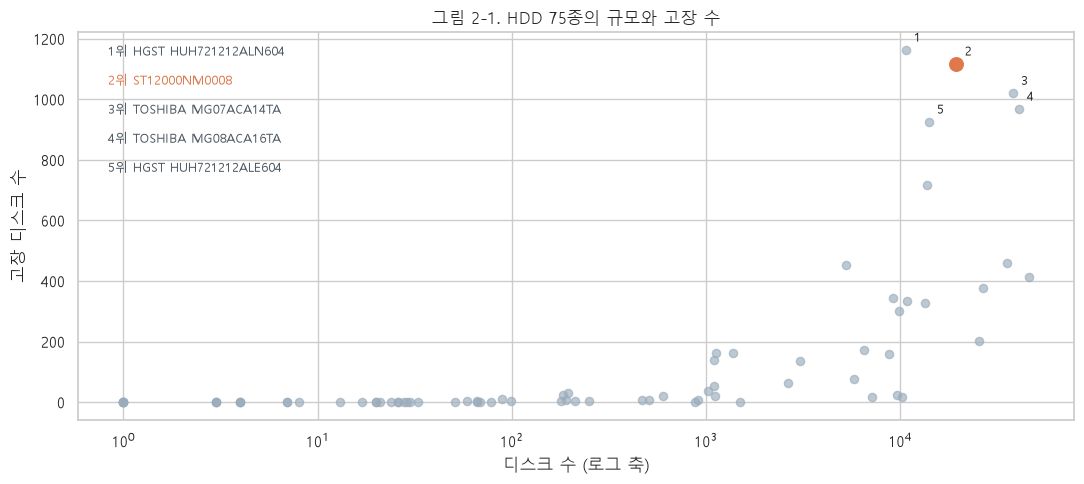

,저장 타입,설명
변수,,
date,date32[day],관측 날짜
serial_number,string,디스크 식별자
model,string,HDD 제품명
capacity_bytes,int64,"용량(byte), -1은 오류·누락"
failure,int64,관측일 고장 표시(0/1)
datacenter,string,센터
smart_1_raw,int64,읽기 오류 지표(1)
smart_5_raw,int64,재할당 섹터(5)
smart_7_raw,int64,탐색 오류 지표(7)


In [2]:
parquet=pq.ParquetFile(source)
scope=pd.DataFrame({
    '전체 HDD':[len(hdd),hdd.disks.sum(),hdd.failed_disks.sum(),hdd.drive_days.sum()],
    '상세 분석':[1,selected.disks,selected.failed_disks,parquet.metadata.num_rows]
},index=['모델 수','디스크 수','고장 디스크 수','일별 기록 수'])
display(scope)
print(f'기간: {selected.first_date} ~ {selected.last_date} / 열 {len(parquet.schema_arrow)}개 / Parquet {source.stat().st_size/1024**2:.1f} MiB')
print(f'SSD·가상 디스크 제외: {len(rank)-len(hdd)}종 / 분석 제품 비중: {100*selected.disks/hdd.disks.sum():.2f}%')

fig,ax=plt.subplots(figsize=(11,5))
ax.scatter(hdd.disks,hdd.failed_disks,c='#9aacbb',s=35,alpha=.65)
ax.scatter(selected.disks,selected.failed_disks,c=COLORS[1],s=95,label=MODEL,zorder=3)
for i,(_,row) in enumerate(hdd.nlargest(5,'failed_disks').iterrows(),1):
    ax.annotate(str(i),(row.disks,row.failed_disks),xytext=(6,6),textcoords='offset points',fontsize=9)
    ax.text(.03,.94-.075*(i-1),f'{i}위 {row.model}',transform=ax.transAxes,fontsize=9,
        color=COLORS[1] if row.model==MODEL else '#4d5861')
ax.set(xscale='log',xlabel='디스크 수 (로그 축)',ylabel='고장 디스크 수',
    title='그림 2-1. HDD 75종의 규모와 고장 수')
show(fig,'2-1_model_scatter')

meaning={'date':'관측 날짜','serial_number':'디스크 식별자','model':'HDD 제품명',
    'capacity_bytes':'용량(byte), -1은 오류·누락','failure':'관측일 고장 표시(0/1)','datacenter':'센터'}
meaning.update({f'smart_{n}_raw':label(n) for n in NAMES})
dictionary=pd.DataFrame([{'변수':field.name,'저장 타입':str(field.type),
    '설명':meaning[field.name]} for field in parquet.schema_arrow])
display(dictionary.set_index('변수'))

**관찰 결과:** 고장 사례가 많은 제품 중 SMART 후보 5종을 기록하는 한 제품을 첫 대상으로 삼았다.

**후속 조치:** 고장 수·기록량은 선정 근거이며 제품 간 예측 성능 우열은 별도 검증한다.

SMART 뜻은 [데이터 사전](../data/backblaze/README.md)을 따른다.
초기 후보 5·187·188·197·198은 [Backblaze의 2016년 글](https://www.backblaze.com/blog/what-smart-stats-indicate-hard-drive-failures/)을 참고했다. 모든 HDD의 필수 지표나 해당 제품의 성능 검증 결과는 아니다.

## 3. 데이터 품질
**질문:** 결측·중복·이상값 때문에 해석이 달라질까?

,결측 수,결측률(%)
변수,,
읽기 오류 지표(1),724,0.005
재할당 섹터(5),724,0.005
탐색 오류 지표(7),724,0.005
가동시간(9),724,0.005
보고된 복구 불가 오류(187),724,0.005
명령 시간 초과(188),724,0.005
헤드 높이 관련 쓰기(189),15506879,100.000
공기 흐름 온도(190),724,0.005
헤드 적재·해제(193),724,0.005


,행 수
디스크·날짜 중복,0
용량 음수,684
보류(197)·복구 불가(198) 차이,0
온도(190)·온도(194) 차이,0


,재할당 섹터(5),보고된 복구 불가 오류(187),보류 섹터(197),온도(194)
count,510632.00,510632.00,510632.00,510632.00
mean,132.13,2.71,1.09,31.62
std,1669.16,157.27,108.30,5.78
min,0.00,0.00,0.00,16.00
50%,0.00,0.00,0.00,32.00
95%,8.00,0.00,0.00,41.00
max,65216.00,65535.00,59544.00,57.00


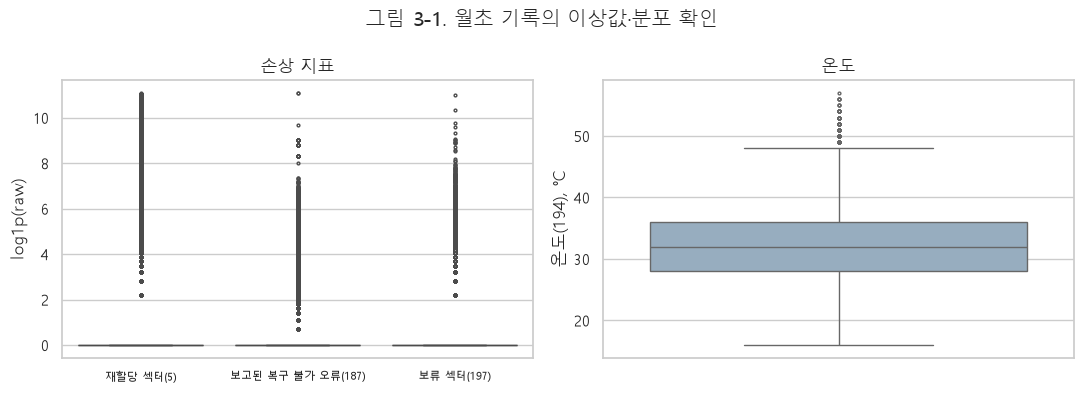

In [3]:
# 필요한 열만 읽고, 원본 21개 열의 결측은 Parquet 메타데이터로 확인한다.
smart=[5,9,187,188,190,194,197,198]
cols=['date','serial_number','model','datacenter','failure','capacity_bytes']+[f'smart_{n}_raw' for n in smart]
d=pd.read_parquet(source,columns=cols,dtype_backend='pyarrow')
assert d.model.isin(hdd.model).all() and d.model.eq(MODEL).all()
d['date']=pd.to_datetime(d.date)
for col in ['serial_number','model','datacenter']:
    d[col]=d[col].astype('category')
for col in d.select_dtypes(include='number').columns:
    d[col]=pd.to_numeric(d[col],downcast='unsigned')

missing=[]
for i,field in enumerate(parquet.schema_arrow):
    counts=[parquet.metadata.row_group(g).column(i).statistics.null_count for g in range(parquet.num_row_groups)]
    missing.append({'변수':meaning[field.name],'결측 수':sum(counts)})
missing=pd.DataFrame(missing)
missing['결측률(%)']=100*missing['결측 수']/len(d)
display(missing[missing['결측 수']>0].round(3).set_index('변수'))
duplicates=int(d.duplicated(['serial_number','date']).sum())
checks=pd.Series({
    '디스크·날짜 중복':duplicates,
    '용량 음수':int(d.capacity_bytes.lt(0).sum()),
    '보류(197)·복구 불가(198) 차이':int((d.smart_197_raw.isna().ne(d.smart_198_raw.isna()) | d.smart_197_raw.ne(d.smart_198_raw).fillna(False)).sum()),
    '온도(190)·온도(194) 차이':int((d.smart_190_raw.isna().ne(d.smart_194_raw.isna()) | d.smart_190_raw.ne(d.smart_194_raw).fillna(False)).sum())
},name='행 수')
display(checks.to_frame())
assert duplicates==0, '중복·상충 기록을 먼저 확인하세요.'

monthly=d.loc[d.date.dt.is_month_start,[f'smart_{n}_raw' for n in [5,187,197,194]]].astype(float)
display(monthly.rename(columns={f'smart_{n}_raw':label(n) for n in [5,187,197,194]}).describe(percentiles=[.5,.95]).round(2))
fig,axes=plt.subplots(1,2,figsize=(11,4))
damage=np.log1p(monthly[['smart_5_raw','smart_187_raw','smart_197_raw']]).rename(columns={f'smart_{n}_raw':label(n) for n in [5,187,197]})
sns.boxplot(data=damage,ax=axes[0],color='#90aec6',fliersize=2)
sns.boxplot(y=monthly.smart_194_raw,ax=axes[1],color='#90aec6',fliersize=2)
axes[0].set(ylabel='log1p(raw)',title='손상 지표')
axes[0].tick_params(axis='x',labelsize=8)
axes[1].set(ylabel='온도(194), ℃',title='온도')
fig.suptitle('그림 3-1. 월초 기록의 이상값·분포 확인')
show(fig,'3-1_outliers')

**관찰 결과:** 중복은 0행. 결측·중복 지표가 있고 손상 지표는 극단값이 나타난다.

**후속 조치:** 결측과 0을 구분한다. 전부 결측(189)·중복(190·198)은 입력 제외 후보이며 극단값은 일괄 삭제하지 않는다.

## 4. 시계열 확인
**질문:** HDD별 기록이 매일 이어지고 관측 기간도 충분할까?

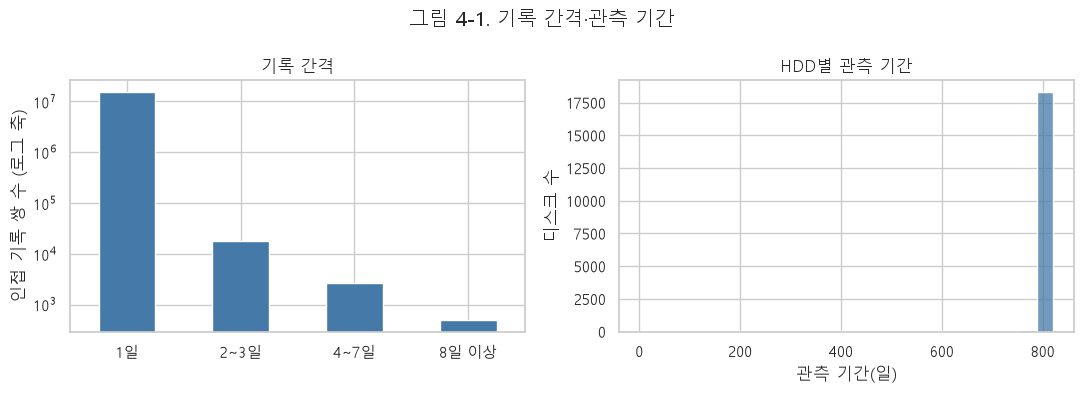

,관측기간(일),기록확보율(%)
count,19516.00,19516.00
mean,796.56,99.74
std,111.31,0.81
min,1.00,66.67
25%,821.00,99.76
50%,821.00,99.88
75%,821.00,100.00
max,821.00,100.00


In [4]:
life=d.groupby('serial_number',observed=True,sort=False).date.agg(['min','max','size'])
life.columns=['시작','종료','기록수']
life['관측기간(일)']=(life.종료-life.시작).dt.days+1
life['기록확보율(%)']=100*life.기록수/life['관측기간(일)']
gap=d.groupby('serial_number',observed=True,sort=False).date.diff().dt.days.astype('float32')
assert gap.dropna().ge(1).all(), '날짜 정렬·중복을 확인하세요.'
interval=pd.Series({'1일':gap.eq(1).sum(),'2~3일':gap.between(2,3).sum(),
    '4~7일':gap.between(4,7).sum(),'8일 이상':gap.gt(7).sum()})
fig,axes=plt.subplots(1,2,figsize=(11,4))
interval.plot.bar(ax=axes[0],color=COLORS[0],rot=0,logy=True)
axes[0].set(title='기록 간격',ylabel='인접 기록 쌍 수 (로그 축)')
sns.histplot(life['관측기간(일)'],bins=25,ax=axes[1],color=COLORS[0])
axes[1].set(title='HDD별 관측 기간',xlabel='관측 기간(일)',ylabel='디스크 수')
fig.suptitle('그림 4-1. 기록 간격·관측 기간')
show(fig,'4-1_record_coverage')
display(life[['관측기간(일)','기록확보율(%)']].describe().round(2))

**관찰 결과:** 인접 기록의 99.86%가 1일 간격. 기간 안의 누락은 38,716 디스크-일이다.

**후속 조치:** 7일·30일 변화량은 실제 과거 날짜와 연결하고 누락을 0으로 채우지 않는다. 첫 관측일은 구매일이 아니다.

## 5. 고장 현황
**질문:** 정상·고장 비율은 얼마나 불균형하고 모델별 차이는?

AFR은 첫 고장 디스크 수 ÷ 디스크-일 × 365 × 100으로 연간 환산한다.

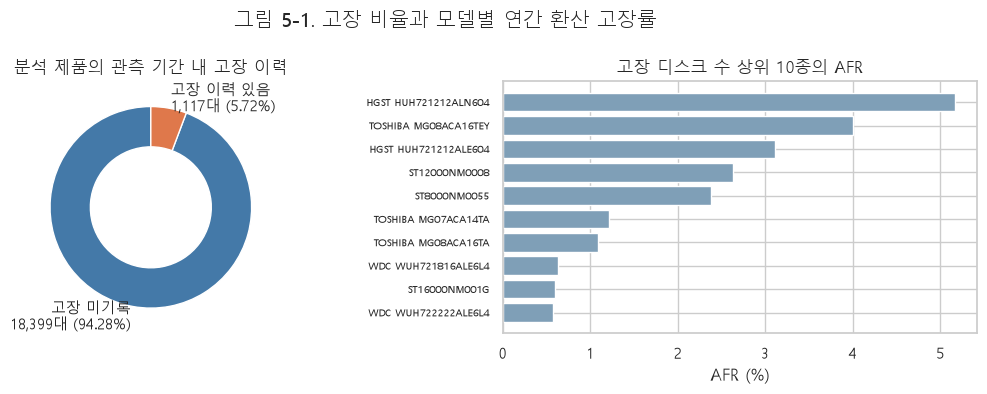

첫 고장 1,117대 / 첫 고장일 이후 제외 대상 1,719행


In [5]:
first_failure=d.loc[d.failure.eq(1)].groupby('serial_number',observed=True).date.min()
failure_day=pd.to_datetime(d.serial_number.map(first_failure))
post_failure=failure_day.notna() & d.date.gt(failure_day)
status=pd.Series({'고장 미기록':len(life)-len(first_failure),'고장 이력 있음':len(first_failure)})
fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].pie(status.values,labels=[f'{name}\n{value:,}대 ({100*value/status.sum():.2f}%)' for name,value in status.items()],
    colors=COLORS,startangle=90,wedgeprops={'width':.4})
axes[0].set_title('분석 제품의 관측 기간 내 고장 이력')
top=hdd.nlargest(10,'failed_disks').copy()
top['afr_pct']=36500*top.failed_disks/top.drive_days
top=top.sort_values('afr_pct')
axes[1].barh(top.model,top.afr_pct,color='#7f9fb7')
axes[1].set(xlabel='AFR (%)',title='고장 디스크 수 상위 10종의 AFR')
axes[1].tick_params(axis='y',labelsize=7)
fig.suptitle('그림 5-1. 고장 비율과 모델별 연간 환산 고장률')
show(fig,'5-1_failure_status')
print(f'첫 고장 {len(first_failure):,}대 / 첫 고장일 이후 제외 대상 {post_failure.sum():,}행')

**관찰 결과:** 고장 미기록은 영구 정상이 아니다. 분석 제품의 관측 기간 고장 비율은 5.72%.

**후속 조치:** 고장 건수와 AFR을 구분한다. 날짜·가동시간이 다른 모델의 수치를 제품 성능 차이로 단정하지 않는다.

## 6. 고장 전 변화
**질문:** 고장 전 90일 동안 SMART가 변하고 마지막 30일에 차이가 보일까?

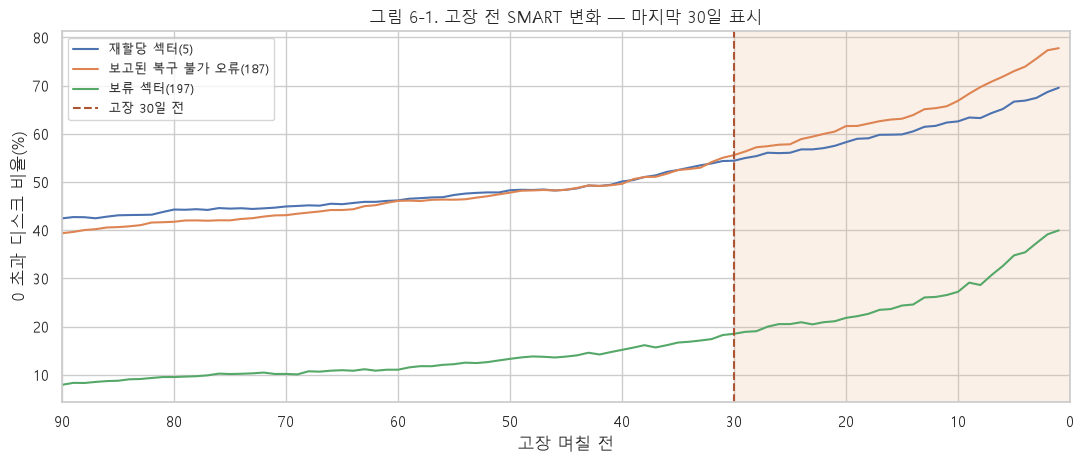

,재할당 섹터(5),보고된 복구 불가 오류(187),보류 섹터(197)
고장며칠전,,,
90.0,42.446043,39.362795,7.913669
60.0,46.169154,46.069652,11.044776
30.0,54.404647,55.566312,18.489835
7.0,64.292879,70.812437,30.692076
1.0,69.546436,77.75378,39.956803


In [6]:
days_before=(failure_day-d.date).dt.days.astype('float32')
near=days_before.between(1,90)
trajectory=d.loc[near,[f'smart_{n}_raw' for n in [5,187,197]]].astype(float)
trajectory['고장며칠전']=days_before[near]
flags=trajectory.drop(columns='고장며칠전').gt(0).where(trajectory.drop(columns='고장며칠전').notna())
trend=flags.groupby(trajectory.고장며칠전).mean()*100
trend.columns=[label(n) for n in [5,187,197]]
fig,ax=plt.subplots(figsize=(11,4.8))
trend.plot(ax=ax)
ax.axvspan(0,30,color='#edb78f',alpha=.2)
ax.axvline(30,color='#ad5532',ls='--',label='고장 30일 전')
ax.set(xlim=(90,0),xlabel='고장 며칠 전',ylabel='0 초과 디스크 비율(%)',
    title='그림 6-1. 고장 전 SMART 변화 — 마지막 30일 표시')
ax.legend(fontsize=9)
show(fig,'6-1_before_failure_30days')
display(trend.loc[[90,60,30,7,1]].round(1))

**관찰 결과:** 재할당 섹터(5)의 0 초과 비율은 고장 90일 전 42.4% → 전날 69.5%.

**후속 조치:** 현재 값뿐 아니라 최근 증가량을 후보로 둔다. 실제 고장일은 정렬용 사후 정보이며 입력에 넣지 않는다.

시점마다 관측·유효값이 있는 디스크 수가 달라질 수 있다. 궤적은 고장 디스크만의 기술통계이며 30일 예측 성능은 아니다.

## 7. 변수 관계
**질문:** 피처끼리 겹치는 정보와 30일 예측에 쓸 신호는?

월초 표본에서 비교한다. ‘정상’은 30일 뒤까지 관측되고 그 기간 고장 기록이 없는 경우다.
미래 확인 불가 음성과 전체 데이터 마지막 30일은 제외한다.

### 전체 컬럼 상관 확인

원본 **21개 열**을 점검했다. 식별자·날짜·센터, 상수인 용량·고장 당일 표시, 전부 결측인 189는 제외한다.
월초 유효 표본 **492,147행**에서 수치 피처 14개를 계산하고, 그림은 완전 중복 2개를 뺀 12개를 보여준다.

,유효 고유값 수,처리
변수,,
capacity_bytes,1,상수 → 제외
failure,1,상수 → 제외
smart_1_raw,488192,상관분석 포함
smart_5_raw,1391,상관분석 포함
smart_7_raw,491983,상관분석 포함
smart_9_raw,31471,상관분석 포함
smart_187_raw,463,상관분석 포함
smart_188_raw,1590,상관분석 포함
smart_189_raw,0,전부 결측 → 제외


,변수 A,변수 B,Spearman
0,공기 흐름 온도(190),온도(194),1.0
1,보류 섹터(197),복구 불가 섹터(198),1.0


,변수 A,변수 B,Spearman
0,가동시간(9),누적 쓰기 블록(241),0.809
1,가동시간(9),누적 읽기 블록(242),0.659
2,누적 쓰기 블록(241),누적 읽기 블록(242),0.632
3,가동시간(9),헤드 적재·해제(193),0.558
4,헤드 적재·해제(193),누적 쓰기 블록(241),0.514
5,재할당 섹터(5),보고된 복구 불가 오류(187),0.467
6,헤드 적재·해제(193),누적 읽기 블록(242),0.388
7,명령 시간 초과(188),전송 CRC 오류(199),0.366
8,보고된 복구 불가 오류(187),보류 섹터(197),0.342
9,온도(194),누적 쓰기 블록(241),0.286


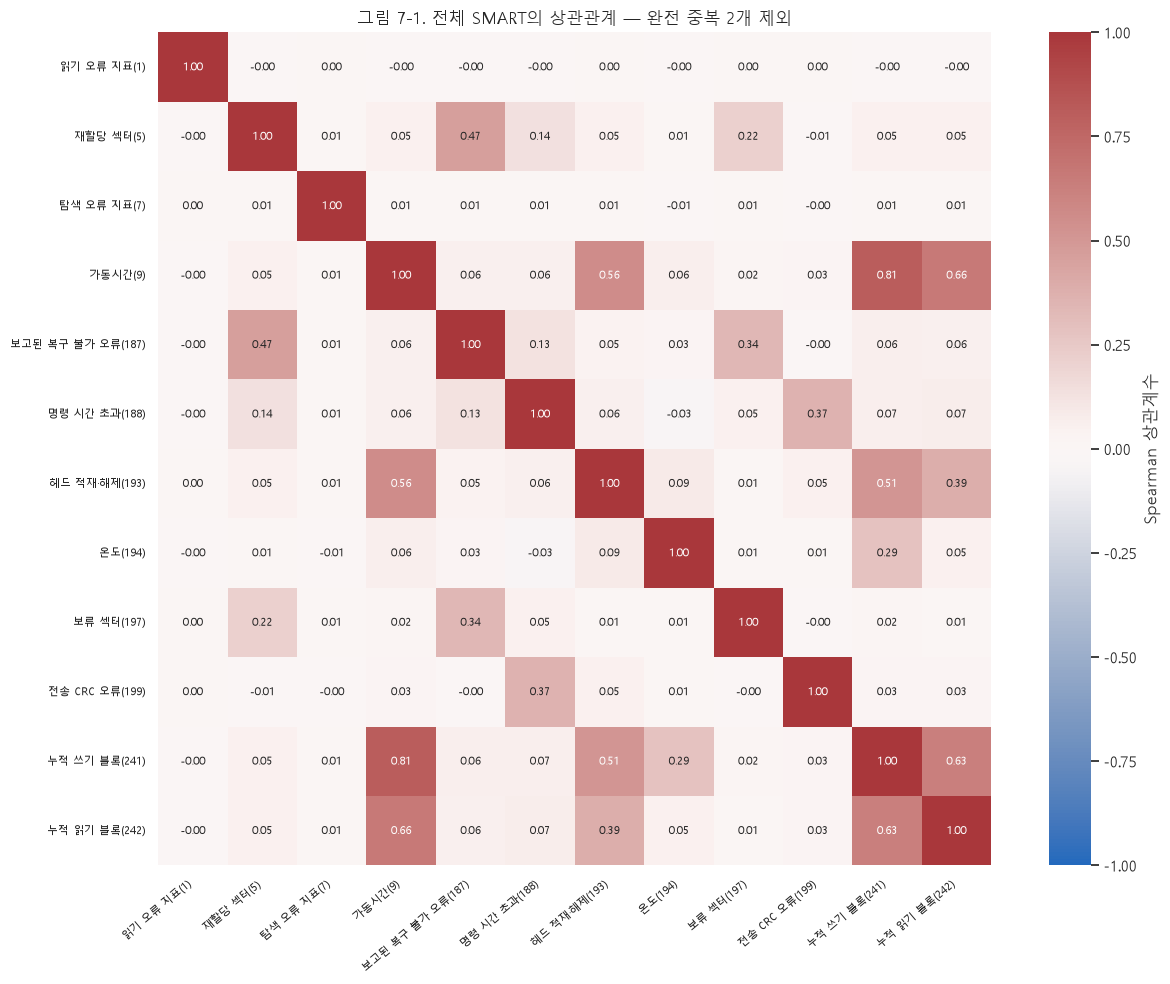

In [7]:

# 전체 열을 확인하되, 메모리를 아끼기 위해 월초 기록만 모은다.
monthly_parts=[]
last_parts=[]
failed_parts=[]
for batch in pq.ParquetFile(source).iter_batches(batch_size=131072):
    part=batch.to_pandas(types_mapper=pd.ArrowDtype)
    part['date']=pd.to_datetime(part.date)
    last_parts.append(part.groupby('serial_number').date.max())
    failed_parts.append(part.loc[part.failure.eq(1),['serial_number','date']])
    monthly_parts.append(part.loc[part.date.dt.is_month_start].copy())
last_seen=pd.concat(last_parts).groupby(level=0).max()
first_fail=pd.concat(failed_parts).groupby('serial_number').date.min()
all_month=pd.concat(monthly_parts,ignore_index=True)
del monthly_parts,last_parts,failed_parts,part,batch
fd=pd.to_datetime(all_month.serial_number.map(first_fail))
end=pd.to_datetime(all_month.serial_number.map(last_seen))
future=(fd-all_month.date).dt.days
usable=(fd.isna() | all_month.date.lt(fd)) & (future.between(1,30) | end.ge(all_month.date+pd.Timedelta(days=30)))
usable &= all_month.date.le(last_seen.max()-pd.Timedelta(days=30))
all_month=all_month.loc[usable].copy()

# 식별자·날짜·센터는 상관 피처에서 제외하고, 용량 -1은 결측으로 처리한다.
excluded=['date','serial_number','model','datacenter']
values=all_month.drop(columns=excluded).apply(pd.to_numeric,errors='coerce').astype(float)
values['capacity_bytes']=values.capacity_bytes.where(values.capacity_bytes.ge(0))
unique=values.nunique()
audit=pd.DataFrame({'변수':values.columns,'유효 고유값 수':unique.values})
audit['처리']=np.where(audit['유효 고유값 수'].eq(0),'전부 결측 → 제외',
    np.where(audit['유효 고유값 수'].eq(1),'상수 → 제외','상관분석 포함'))
display(audit.set_index('변수'))
values=values.loc[:,unique.gt(1)]
full_corr=values.corr(method='spearman')

# 완전 중복 두 쌍은 계산으로 확인한 뒤 그림에서는 한쪽을 생략한다.
duplicate_cols=[]
duplicate_rows=[]
for a,b in [('smart_190_raw','smart_194_raw'),('smart_197_raw','smart_198_raw')]:
    r=full_corr.loc[a,b]
    duplicate_rows.append({'변수 A':label(int(a.split('_')[1])),
        '변수 B':label(int(b.split('_')[1])),'Spearman':r})
    if np.isclose(r,1):
        duplicate_cols.append(a if a=='smart_190_raw' else b)
display(pd.DataFrame(duplicate_rows).round(4))
corr=full_corr.drop(index=duplicate_cols,columns=duplicate_cols)
pairs=corr.where(np.triu(np.ones(corr.shape),k=1).astype(bool)).stack().rename('Spearman').reset_index()
pairs.columns=['변수 A','변수 B','Spearman']
pairs=pairs.iloc[pairs.Spearman.abs().sort_values(ascending=False).index].reset_index(drop=True)
for col in ['변수 A','변수 B']:
    pairs[col]=pairs[col].map(lambda c:label(int(c.split('_')[1])))
display(pairs.head(10).round(3))
names={c:label(int(c.split('_')[1])) for c in corr.columns}
fig,ax=plt.subplots(figsize=(13,10))
sns.heatmap(corr.rename(index=names,columns=names),annot=True,fmt='.2f',
    vmin=-1,vmax=1,center=0,cmap='vlag',square=True,ax=ax,
    annot_kws={'size':8},cbar_kws={'label':'Spearman 상관계수'})
ax.set_title('그림 7-1. 전체 SMART의 상관관계 — 완전 중복 2개 제외')
plt.setp(ax.get_xticklabels(),rotation=40,ha='right',fontsize=8)
plt.setp(ax.get_yticklabels(),rotation=0,fontsize=8)
show(fig,'7-1_correlation')
del all_month,values,fd,end,future,usable

**관찰 결과:** 가동시간(9)–누적 쓰기(241) **0.809**, 가동시간(9)–누적 읽기(242) **0.659**, 누적 쓰기(241)–누적 읽기(242) **0.632**다. 사용 시간·누적 사용량이 함께 움직인다. 온도 190–194와 섹터 197–198은 각각 **1.00인 중복 쌍**이다.

**후속 조치:** 중복 지표는 한쪽을 제외하고, 가동시간·누적 사용량은 조합별로 검증한다. 높은 피처 간 상관이 고장 예측력이 높다는 뜻은 아니다.

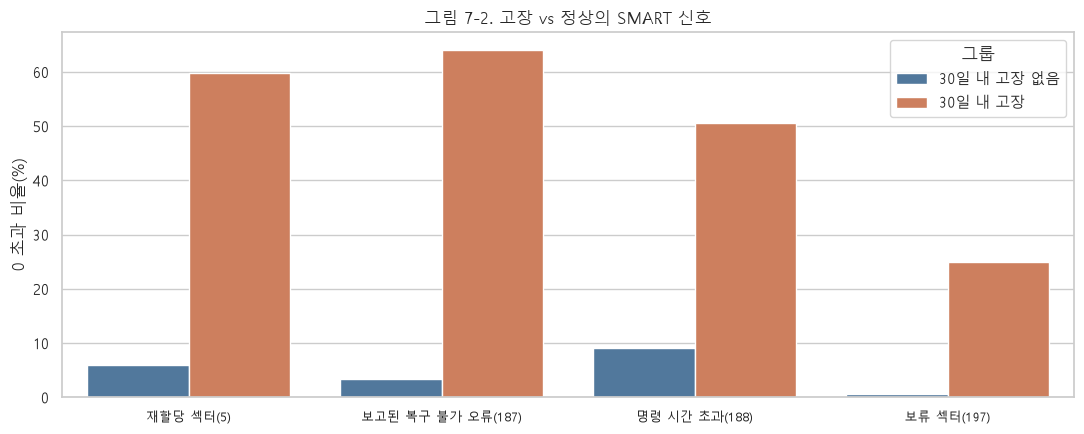

In [8]:
before_failure=failure_day.isna() | d.date.lt(failure_day)
sample_cols=['date','serial_number','smart_5_raw','smart_9_raw','smart_187_raw',
    'smart_188_raw','smart_194_raw','smart_197_raw']
snap=d.loc[d.date.dt.is_month_start & before_failure,sample_cols].copy()
future=(pd.to_datetime(snap.serial_number.map(first_failure))-snap.date).dt.days
end=pd.to_datetime(snap.serial_number.map(life.종료))
snap['y']=np.where(future.between(1,30),1,np.where(end.ge(snap.date+pd.Timedelta(days=30)),0,np.nan))
snap=snap.loc[snap.y.notna() & snap.date.le(d.date.max()-pd.Timedelta(days=30))].copy()
groups={0:'30일 내 고장 없음',1:'30일 내 고장'}
rates=[]
for n in [5,187,188,197]:
    col=f'smart_{n}_raw'
    part=snap.groupby('y')[col].agg(lambda x:100*x.dropna().gt(0).mean()).reset_index(name='0 초과 비율(%)')
    part['지표']=label(n)
    part['그룹']=part.y.map(groups)
    rates.append(part)
rates=pd.concat(rates,ignore_index=True)
fig,ax=plt.subplots(figsize=(11,4.5))
sns.barplot(data=rates,x='지표',y='0 초과 비율(%)',hue='그룹',hue_order=list(groups.values()),palette=COLORS,ax=ax)
ax.set(title='그림 7-2. 고장 vs 정상의 SMART 신호',xlabel='')
ax.tick_params(axis='x',labelsize=9)
show(fig,'7-2_failure_signals')

**관찰 결과:** 월초 평가 표본의 30일 내 고장 비율은 0.20%. 상관계수는 피처끼리의 관계다.

**후속 조치:** 상관만으로 피처를 삭제하지 않는다. 불균형을 고려하고 시간 분할로 유용성을 검증한다.

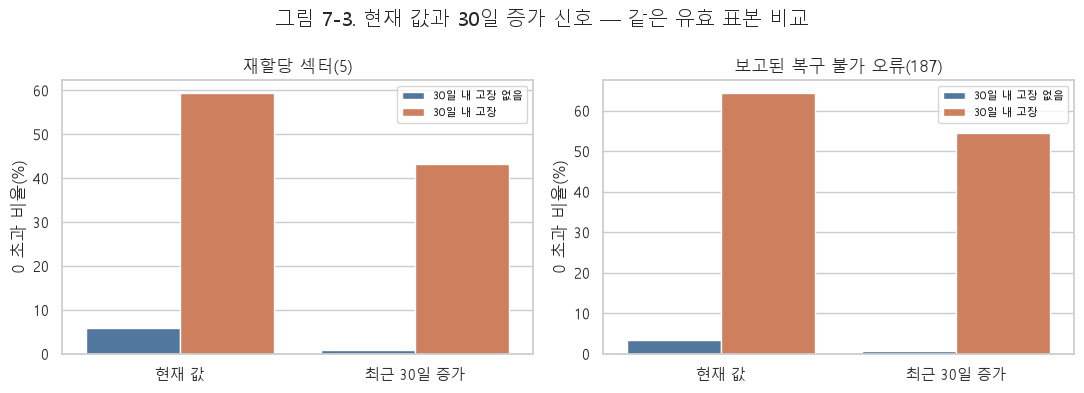

In [9]:
# 정확히 30일 전 기록과 연결한다. 카운터 감소·결측은 증가량 비교에서 제외한다.
past=d[['serial_number','date','smart_5_raw','smart_187_raw']].rename(
    columns={'date':'과거날짜','smart_5_raw':'이전5','smart_187_raw':'이전187'})
snap['과거날짜']=snap.date-pd.Timedelta(days=30)
paired=snap.merge(past,on=['serial_number','과거날짜'],how='left')
growth=[]
for n in [5,187]:
    now=paired[f'smart_{n}_raw'].astype(float)
    previous=paired[f'이전{n}'].astype(float)
    valid=now.ge(previous)
    for y,name in groups.items():
        use=valid & paired.y.eq(y)
        growth.append({'지표':label(n),'그룹':name,'현재 값':100*now[use].gt(0).mean(),
            '최근 30일 증가':100*now[use].gt(previous[use]).mean()})
growth=pd.DataFrame(growth).melt(id_vars=['지표','그룹'],var_name='신호',value_name='0 초과 비율(%)')
fig,axes=plt.subplots(1,2,figsize=(11,4))
for ax,n in zip(axes,[5,187]):
    sns.barplot(data=growth[growth.지표.eq(label(n))],x='신호',y='0 초과 비율(%)',
        hue='그룹',hue_order=list(groups.values()),palette=COLORS,ax=ax)
    ax.set(title=label(n),xlabel='')
    ax.legend(fontsize=8)
fig.suptitle('그림 7-3. 현재 값과 30일 증가 신호 — 같은 유효 표본 비교')
show(fig,'7-3_recent_growth')

**관찰 결과:** 현재 값과 증가 여부는 서로 다른 특징을 담는다.

**후속 조치:** 7일·30일 변화량을 후보로 비교한다. 이 그래프만으로 예측 성능 향상을 확정하지 않는다.

## 8. 결론
**질문:** 무엇을 모델링에 반영하고 무엇을 더 확인할까?

| 주요 발견 | 전처리·모델링 방향 |
|---|---|
| 관측 누락·관측 종료가 존재 | 미래 확인 불가 음성을 제외하고 실제 과거 날짜로 연결 |
| 손상 지표가 고장 전 변함 | 현재 값·0 초과 여부·증가량을 후보로 비교 |
| 일부 지표가 중복·상관을 보임 | 중복과 별개 정보를 구분하고 검증으로 입력 결정 |
| 월초 표본의 30일 고장 비율 약 0.20% | 같은 경보량에서 정밀도·재현율 비교 |

**관찰 결과:** 한 제품의 탐색 결과이며 인과관계·예측 성능을 확정하지 않는다.

**후속 조치:** 시기·센터·가동 연수의 영향을 추가 확인하고 학습→검증→테스트 시간 분할을 적용한다.

같은 시기에 대량 도입한 집단의 노후화 가능성은 가설이다. 구매·설치 이력이 없어 원인으로 확정할 수 없다.
전체 기간 고장 수로 고른 탐색 대상이므로 미래 평가에서는 대상 선정도 학습 기간 기준으로 재검토한다.

근거: [원본 데이터](https://www.backblaze.com/cloud-storage/resources/hard-drive-test-data) · [모델 집계](../data/backblaze/summary/model_rank.csv) · [컬럼 설명](../data/backblaze/README.md).
다른 제품으로 확대하는 근거는 [EDA v2](eda_v3_87%25.ipynb), 기존 모델 설정·결과는 [ML v1](../ml/v1/README.md)에 있다.